![image info](https://user-images.githubusercontent.com/91945811/146929832-e78ff1f4-2739-41b1-acd3-019a39b6a42c.png)

# **Bericht zur Verkaufsdatenanalyse 2019**

## Einleitung – Ziele der Analyse
Die vorliegende Analyse hat das Ziel, die Verkaufsdaten des Jahres 2019 umfassend zu untersuchen. Ziel ist es, wichtige Erkenntnisse zu gewinnen, darunter:
- Identifikation umsatzstarker Produkte und Städte
- Erkennung saisonaler Schwankungen und Verkaufstrends
- Untersuchung des Kaufverhaltens der Kunden
- Analyse von Produktkombinationen
- Identifikation von Anomalien in den Verkaufsdaten
- Ableitung von Handlungsempfehlungen zur Optimierung des Verkaufs

### **Datenverständnis und erste Explorationsanalyse**
- Lade die Datei **exported_sales_2019.csv** in ein Pandas-DataFrame und verschaffe dir einen ersten Überblick.
- Untersuche die Struktur der Daten:
  - Welche Spalten sind enthalten?
  - Welche Datentypen haben die Spalten?
  - Gibt es fehlende Werte oder Inkonsistenzen in den Daten?

In [24]:
# Bibliotheken Laden

import pandas as pd


# Daten einlesen
df = pd.read_csv('exported_sales_2019.csv')

In [25]:
# erste Übersicht der Spalten

display(df)

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
0,248151,AA Batteries (4-pack),4,3.84,09/17/19 14:44,"380 North St, Los Angeles, CA 90001"
1,248152,USB-C Charging Cable,2,11.95,09/29/19 10:19,"511 8th St, Austin, TX 73301"
2,248153,USB-C Charging Cable,1,11.95,09/16/19 17:48,"151 Johnson St, Los Angeles, CA 90001"
3,248154,27in FHD Monitor,1,149.99,09/27/19 07:52,"355 Hickory St, Seattle, WA 98101"
4,248155,USB-C Charging Cable,1,11.95,09/01/19 19:03,"125 5th St, Atlanta, GA 30301"
...,...,...,...,...,...,...
197540,259353,AAA Batteries (4-pack),3,2.99,09/17/19 20:56,"840 Highland St, Los Angeles, CA 90001"
197541,259354,iPhone,1,700.00,09/01/19 16:00,"216 Dogwood St, San Francisco, CA 94016"
197542,259355,iPhone,1,700.00,09/23/19 07:39,"220 12th St, San Francisco, CA 94016"
197543,259356,34in Ultrawide Monitor,1,379.99,09/19/19 17:30,"511 Forest St, San Francisco, CA 94016"


In [26]:
# df anzeigen
df.shape
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 197545 entries, 0 to 197544
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Order ID          197545 non-null  int64  
 1   Product           197545 non-null  str    
 2   Quantity Ordered  197545 non-null  int64  
 3   Price Each        197545 non-null  float64
 4   Order Date        197545 non-null  str    
 5   Purchase Address  197545 non-null  str    
dtypes: float64(1), int64(2), str(3)
memory usage: 9.0 MB


Die Datei enthält **X Zeilen** und **y Spalten**:

Hier soll eine kurze Erläuterung der Spalten stehen

197545 rows × 6 columns

#### **Aufgaben**
1. **Fehlende Werte prüfen**  
   - prüfe, ob es Zeilen mit fehlenden Werten gibt und entferne diese wenn nötig.

2. **Datentypen anpassen**  
   - `Quantity Ordered` und `Price Each` in **numerische Werte** umwandeln.
   - `Order Date` in ein **DateTime-Format** umwandeln.

3. **Transformation der Daten**
   - Extrahiere aus der **Purchase Address** die Stadt und speichere sie in einer neuen Spalte **City**.(Tipp: verwende `split(', ')`)
   - Berechne **Total Sales** (Gesamtumsatz pro Bestellung) und **Month** (Monat der Bestellung). 

4. **Duplikate entfernen**
   - Es gibt **11.893 Duplikate** im Datensatz, die du entfernen musst.

5. **Index zurücksetzten**
   - Damit der Index nach dem Entfernen einiger Einträge wieder passt, musst du den Index noch zurücksetzte.
  

In [27]:
# Fehlende Werte prüfen
print(df.isnull().sum())
df[df['Order ID'].isna()]

Order ID            0
Product             0
Quantity Ordered    0
Price Each          0
Order Date          0
Purchase Address    0
dtype: int64


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address


In [28]:
df['Quantity Ordered'] = pd.to_numeric(df['Quantity Ordered'], errors='coerce')
df['Price Each'] = pd.to_numeric(df['Price Each'], errors='coerce')
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df.info()

/var/folders/zm/jm3r5bf55n35fjx1rcrmsp6m0000gn/T/ipykernel_56500/663136223.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')


<class 'pandas.DataFrame'>
RangeIndex: 197545 entries, 0 to 197544
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Order ID          197545 non-null  int64         
 1   Product           197545 non-null  str           
 2   Quantity Ordered  197545 non-null  int64         
 3   Price Each        197545 non-null  float64       
 4   Order Date        197545 non-null  datetime64[us]
 5   Purchase Address  197545 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(2)
memory usage: 9.0 MB


In [29]:

new_columns = df['Purchase Address'].str.split(',', expand=True) # alternative with .apply(lambda) for-schleifen
df['City'] = new_columns[1].str.strip()
df['State_Zip'] = new_columns[2].str.strip()

df['Total Sales'] = df['Quantity Ordered'] * df['Price Each'] 

df['Month'] = df['Order Date'].dt.month # dt = datetime

df.tail(5)

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,City,State_Zip,Total Sales,Month
197540,259353,AAA Batteries (4-pack),3,2.99,2019-09-17 20:56:00,"840 Highland St, Los Angeles, CA 90001",Los Angeles,CA 90001,8.97,9
197541,259354,iPhone,1,700.00,2019-09-01 16:00:00,"216 Dogwood St, San Francisco, CA 94016",San Francisco,CA 94016,700.00,9
197542,259355,iPhone,1,700.00,2019-09-23 07:39:00,"220 12th St, San Francisco, CA 94016",San Francisco,CA 94016,700.00,9
197543,259356,34in Ultrawide Monitor,1,379.99,2019-09-19 17:30:00,"511 Forest St, San Francisco, CA 94016",San Francisco,CA 94016,379.99,9
197544,259357,USB-C Charging Cable,1,11.95,2019-09-30 00:18:00,"250 Meadow St, San Francisco, CA 94016",San Francisco,CA 94016,11.95,9


In [30]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
197540     True
197541     True
197542     True
197543     True
197544     True
Length: 197545, dtype: bool

In [31]:
df[df.duplicated()]

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,City,State_Zip,Total Sales,Month
21,248171,USB-C Charging Cable,1,11.95,2019-09-05 15:06:00,"705 Hill St, New York City, NY 10001",New York City,NY 10001,11.95,9
656,248787,AA Batteries (4-pack),1,3.84,2019-09-09 12:30:00,"705 Adams St, San Francisco, CA 94016",San Francisco,CA 94016,3.84,9
1814,249895,34in Ultrawide Monitor,1,379.99,2019-09-19 22:14:00,"901 South St, San Francisco, CA 94016",San Francisco,CA 94016,379.99,9
1831,249910,AAA Batteries (4-pack),1,2.99,2019-09-09 18:34:00,"295 Meadow St, San Francisco, CA 94016",San Francisco,CA 94016,2.99,9
2105,250174,Apple Airpods Headphones,1,150.00,2019-09-30 19:32:00,"490 6th St, New York City, NY 10001",New York City,NY 10001,150.00,9
...,...,...,...,...,...,...,...,...,...,...
197540,259353,AAA Batteries (4-pack),3,2.99,2019-09-17 20:56:00,"840 Highland St, Los Angeles, CA 90001",Los Angeles,CA 90001,8.97,9
197541,259354,iPhone,1,700.00,2019-09-01 16:00:00,"216 Dogwood St, San Francisco, CA 94016",San Francisco,CA 94016,700.00,9
197542,259355,iPhone,1,700.00,2019-09-23 07:39:00,"220 12th St, San Francisco, CA 94016",San Francisco,CA 94016,700.00,9
197543,259356,34in Ultrawide Monitor,1,379.99,2019-09-19 17:30:00,"511 Forest St, San Francisco, CA 94016",San Francisco,CA 94016,379.99,9


In [32]:
# Duplikate entfernen

df = df.drop_duplicates()
df.shape


(185652, 10)

In [33]:
# Index zurücksetzen
df= df.reset_index(drop=True)

### **Ergebnisse der Datenbereinigung & Transformation**
- **fehlende Werte** wurden überprüft.
- Die Spalten **Quantity Ordered** und **Price Each** wurden in numerische Werte umgewandelt.
- Die Spalte **Order Date** wurde in ein **DateTime-Format** konvertiert.
- Die **City** wurde aus der **Purchase Address** extrahiert.
- Der **Total Sales** (Gesamtumsatz pro Bestellung) wurde berechnet.
- Der **Month** (Monat der Bestellung) wurde extrahiert.
- Alle **Duplikate** wurden entfernt.

Nach Bereinigung der Daten stehen 185.652 vollständige Bestellungen zur Verfügung.

Die Daten sind nun bereit für die Analyse.

---

## **Deskriptive Statistik und Kennzahlenberechnung**
- Berechne folgende Verkaufskennzahlen:
  - **Gesamtumsatz für das Jahr 2019**
  - **Durchschnittlicher Bestellwert**
  - **Anzahl der Bestellungen pro Monat**
  - **Beliebteste Produktkategorien oder Artikel (nach Anzahl der Verkäufe oder Umsatz)**
  - **Kunden mit dem höchsten Bestellvolumen** (lass dir für die Kunden jeweils die `Purchase Address` ausgeben.)

In [34]:
# Erste deskriptive statistik mit describe():

df.describe()

,Order ID,Quantity Ordered,Price Each,Order Date,Total Sales,Month
count,185652.000000,185652.000000,185652.000000,185652,185652.000000,185652.000000
mean,230397.332299,1.124529,184.507245,2019-07-18 20:48:16.720315,185.599227,7.059762
min,141234.000000,1.000000,2.990000,2019-01-01 03:07:00,2.990000,1.000000
25%,185824.750000,1.000000,11.950000,2019-04-16 20:51:00,11.950000,4.000000
50%,230339.500000,1.000000,14.950000,2019-07-17 19:49:30,14.950000,7.000000
75%,275005.250000,1.000000,150.000000,2019-10-26 05:17:45,150.000000,10.000000
max,319670.000000,9.000000,1700.000000,2019-12-31 23:53:00,3400.000000,12.000000
std,51505.894713,0.443026,332.834950,NaN,333.023492,3.502293


In [35]:
# Gesamtumsatz für das Jahr 2019
umsatz_2019 = df[df["Order Date"].dt.year== 2019]["Total Sales"].sum() 
print(umsatz_2019)

34456867.65


In [36]:
# Durchschnittlicher Bestellwert
AOV = df["Total Sales"].sum()/len(df)
print(AOV )

185.59922677913514


In [37]:
# Anzahl der Bestellungen pro Monat
order_counts = df.groupby('Month').size()
print(order_counts)


Month
1      9665
2     11957
3     15128
4     18257
5     16552
6     13535
7     14275
8     11943
9     11603
10    20249
11    17544
12    24944
dtype: int64


In [38]:
# Beliebteste Produktkategorien oder Artikel (nach Anzahl der Verkäufe und Umsatz)
#fav_product = df.groupby('Product')['Total Sales'].sum().reset_index()
#print(fav_product)
best_seller = df.groupby('Product')['Total Sales'].sum().reset_index()
best_seller = best_seller.sort_values("Total Sales", ascending= False)

print(best_seller)

best_seller2 = df.groupby('Product')['Quantity Ordered'].sum().reset_index()
best_seller2 = best_seller2.sort_values("Quantity Ordered", ascending= False)

print(best_seller2)

                       Product  Total Sales
13          Macbook Pro Laptop   8030800.00
18                      iPhone   4791500.00
14             ThinkPad Laptop   4125958.74
9                 Google Phone   3316800.00
1       27in 4K Gaming Monitor   2432757.62
3       34in Ultrawide Monitor   2352898.08
6     Apple Airpods Headphones   2344950.00
8                Flatscreen TV   1443600.00
7   Bose SoundSport Headphones   1342565.73
2             27in FHD Monitor   1130624.62
16             Vareebadd Phone    826800.00
0                 20in Monitor    453488.77
11          LG Washing Machine    399600.00
10                    LG Dryer    387600.00
12    Lightning Charging Cable    346286.85
15        USB-C Charging Cable    285927.65
17            Wired Headphones    246034.80
4        AA Batteries (4-pack)    106041.60
5       AAA Batteries (4-pack)     92633.19
                       Product  Quantity Ordered
5       AAA Batteries (4-pack)             30981
4        AA Batteries 

In [39]:
# Kunden mit dem höchsten Bestellvolumen
top_spenders = df.groupby('Purchase Address')['Total Sales'].sum().sort_values(ascending=False)
print(top_spenders.head(10))

Purchase Address
668 Park St, San Francisco, CA 94016        4379.99
795 1st St, Atlanta, GA 30301               4100.00
391 1st St, Seattle, WA 98101               4100.00
731 11th St, New York City, NY 10001        3919.88
208 Chestnut St, San Francisco, CA 94016    3789.99
949 Hickory St, New York City, NY 10001     3779.99
611 Wilson St, San Francisco, CA 94016      3718.78
610 14th St, Los Angeles, CA 90001          3699.98
256 Hill St, San Francisco, CA 94016        3561.95
797 Dogwood St, San Francisco, CA 94016     3552.99
Name: Total Sales, dtype: float64


### **Ergebnisse der deskriptiven Statistik & Kennzahlenberechnung**
1. **Gesamtumsatz für das Jahr 2019:** **34.46 Millionen USD**
2. **Durchschnittlicher Bestellwert:** **185.6 USD**
3. **Anzahl der Bestellungen pro Monat:**
   - Höchste Anzahl an Bestellungen: **Dezember (24.944 Bestellungen)**
   - Niedrigste Anzahl an Bestellungen: **Januar (9.665 Bestellungen)**
4. **Top 10 meistverkaufte Produkte (nach Anzahl der Verkäufe):**
   - **AAA Batteries (4-pack):** 30.981 Einheiten
   - **AA Batteries (4-pack):** 27.615 Einheiten
   - **USB-C Charging Cable:** 23.927 Einheiten
   - **Lightning Charging Cable:** 23.163 Einheiten
   - **Wired Headphones:** 20.520 Einheiten
   - **Apple Airpods Headphones:** 15.633 Einheiten
   - **Bose SoundSport Headphones:** 13.427 Einheiten
   - **27in FHD Monitor:** 7.538 Einheiten
   - **iPhone:** 6.845 Einheiten
   - **27in 4K Gaming Monitor:** 6.238 Einheiten

5. **Top 10 umsatzstärkste Produkte (nach Umsatz):**
   - **Macbook Pro Laptop:** **8.03 Mio. USD**
   - **iPhone:** **4.79 Mio. USD**
   - **ThinkPad Laptop:** **4.13 Mio. USD**
   - **Google Phone:** **3.32 Mio. USD**
   - **27in 4K Gaming Monitor:** **2.43 Mio. USD**
   - **34in Ultrawide Monitor:** **2.35 Mio. USD**
   - **Apple Airpods Headphones:** **2.34 Mio. USD**
   - **Flatscreen TV:** **1.44 Mio. USD**
   - **Bose SoundSport Headphones:** **1.34 Mio. USD**
   - **27in FHD Monitor:** **1.13 Mio. USD**

6. **Kunden mit dem höchsten Bestellvolumen:**
   - **Höchste Bestellsumme:** **4.379,99 USD** (San Francisco, CA)
   - **Zweitgrößte Bestellsumme:** **4.100,00 USD** (Seattle, WA sowie Atlanta, GA)
   - Weitere Städte mit hoher Bestellsumme: **New York City, San Francisco, Los Angeles**

---

## **Datenvisualisierung**

Erstelle verschiedene Diagramme zur Visualisierung der Verkaufsdaten
- Liniendiagramm: Anzahl Bestellungen pro Monat
- Balkendiagramm: Umsatz pro Produktkategorie, sowie die beliebtesten Produkte (Anzahl Verkäufe)
- Histogramm: Verteilung der Bestellwerte
- Balkendiagamm: Wochentag vs. Umsatz (Gibt es umsatzstarke Tage?)
- Balkendiagramm: Verteilung der Bestellungen pro Stunde

Welche Muster kannst du aus den Diagrammen ableiten?

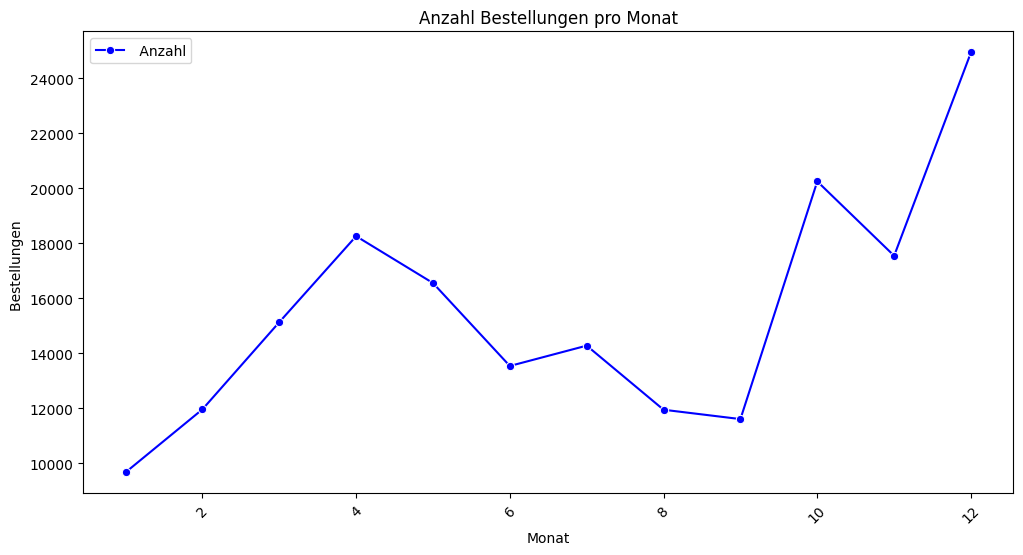

In [40]:
# Umsatzentwicklung pro Monat (Liniendiagramm)
import matplotlib.pyplot as plt
import seaborn as sns
order_counts = df.groupby('Month').size().reset_index(name='order_counts')

plt.figure(figsize=(12, 6))
sns.lineplot( data = order_counts, x="Month", y="order_counts", marker="o", color="b", label=" Anzahl")
plt.ylabel("Bestellungen ")
plt.xlabel("Monat")
plt.title("Anzahl Bestellungen pro Monat")
plt.xticks(rotation=45)
plt.legend()
plt.show()

/var/folders/zm/jm3r5bf55n35fjx1rcrmsp6m0000gn/T/ipykernel_56500/1049049489.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=best_seller, x='Total Sales', y='Product', palette='viridis')


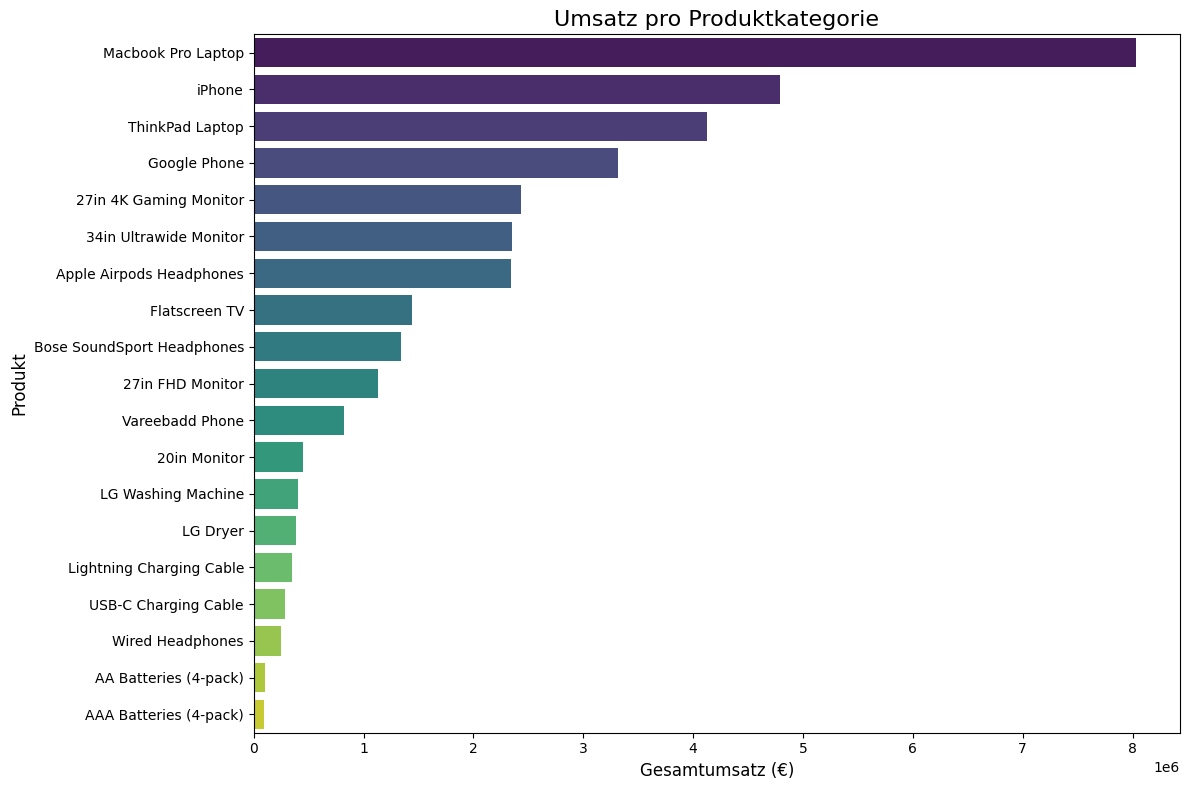

In [41]:
# Umsatz pro Produktkategorie (Balkendiagramm)

plt.figure(figsize=(12, 8))
sns.barplot(data=best_seller, x='Total Sales', y='Product', palette='viridis')

plt.title('Umsatz pro Produktkategorie', fontsize=16)
plt.xlabel('Gesamtumsatz (€)', fontsize=12)
plt.ylabel('Produkt', fontsize=12)


plt.tight_layout()
plt.show()

/var/folders/zm/jm3r5bf55n35fjx1rcrmsp6m0000gn/T/ipykernel_56500/701481555.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=best_seller2, x='Quantity Ordered', y='Product', palette='viridis')


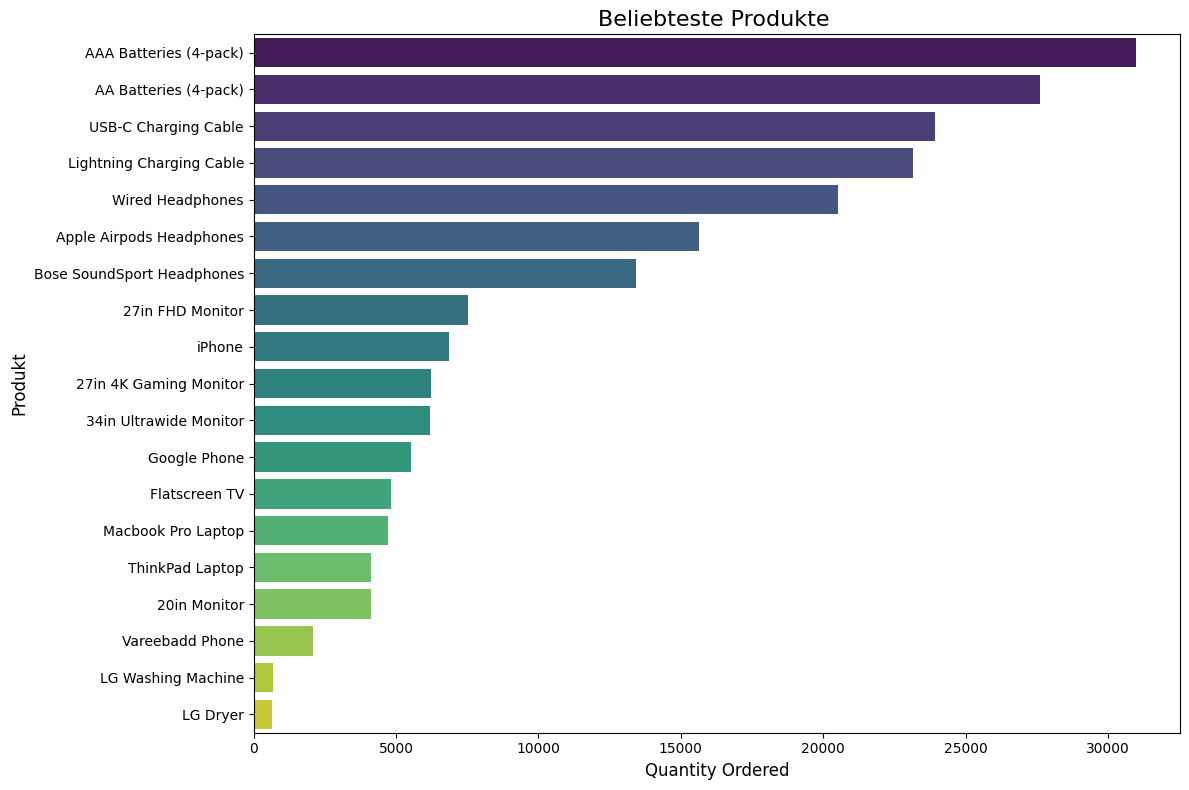

In [42]:
# Beliebteste Produkte (Balkendiagramm)
plt.figure(figsize=(12, 8))
sns.barplot(data=best_seller2, x='Quantity Ordered', y='Product', palette='viridis')

plt.title('Beliebteste Produkte ', fontsize=16)
plt.xlabel('Quantity Ordered', fontsize=12)
plt.ylabel('Produkt', fontsize=12)


plt.tight_layout()
plt.show()

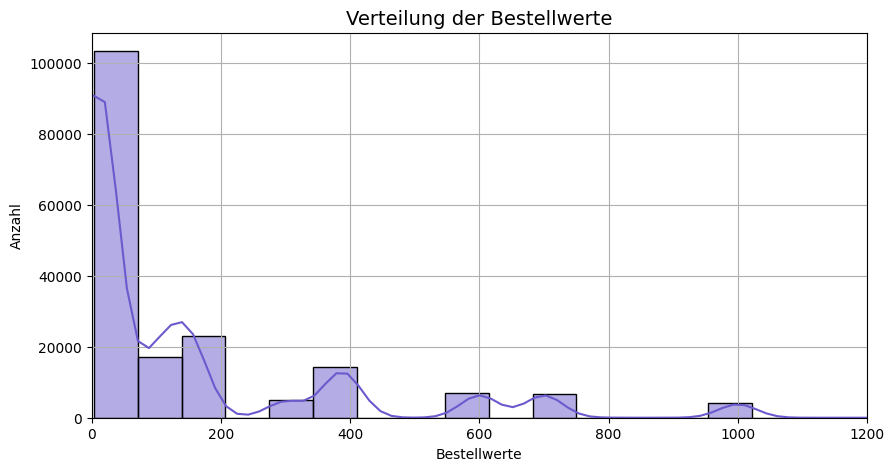

In [43]:
# Histogramm: Verteilung der Bestellwerte
plt.figure(figsize=(10, 5))
sns.histplot(data = df, x = 'Total Sales', bins=50, color="slateblue", edgecolor="black", kde=True)
plt.xlim(0,1200)
plt.title("Verteilung der Bestellwerte", fontsize=14)
plt.xlabel("Bestellwerte")
plt.ylabel("Anzahl")
plt.grid(True)
plt.show()

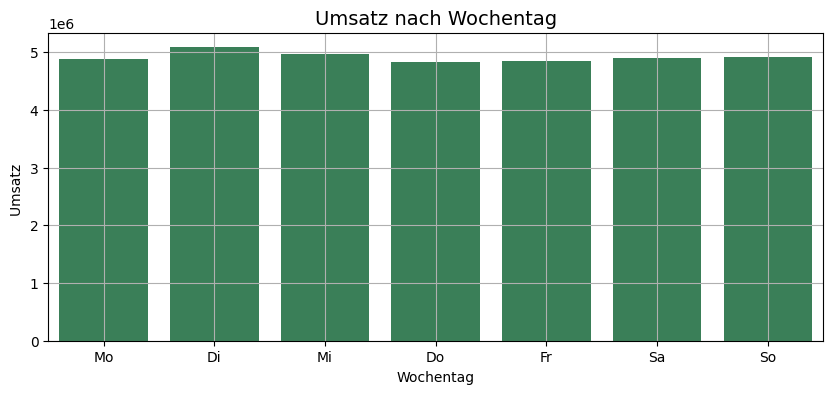

In [44]:
# Balkendiagramm: Umsatz nach Wochentag
df['review_weekday'] = df['Order Date'].dt.weekday
weekday_sales = df.groupby('review_weekday')['Total Sales'].sum().reset_index()

plt.figure(figsize=(10, 4))
weekday_labels = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]
sns.barplot(data=weekday_sales, x="review_weekday",y='Total Sales', color="seagreen")
plt.title("Umsatz nach Wochentag", fontsize=14)
plt.xlabel("Wochentag")
plt.ylabel("Umsatz ")
plt.xticks(ticks=range(7), labels=weekday_labels)
plt.grid(True)
plt.show()

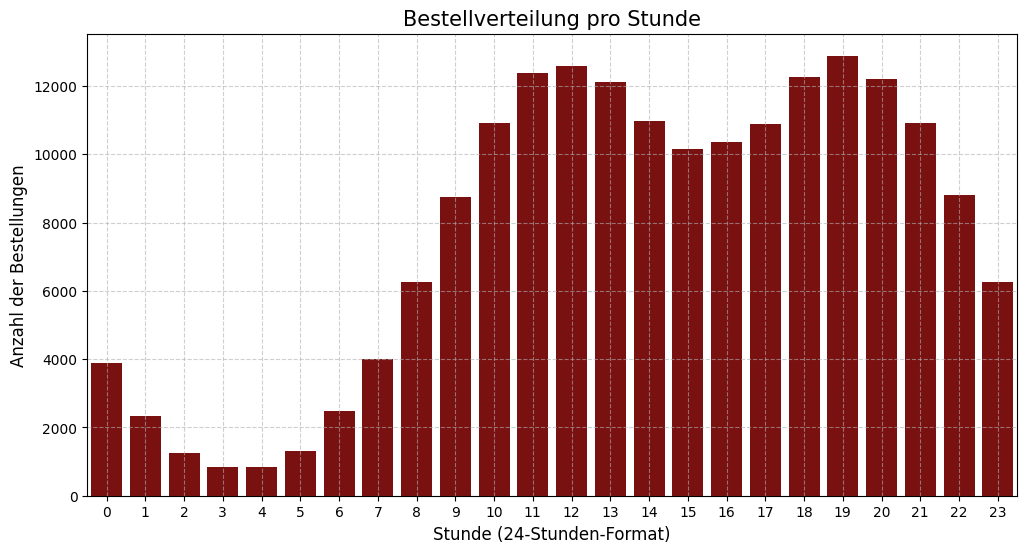

<bound method DataFrame.info of     Hour  Order ID
0      0      3890
1      1      2338
2      2      1238
3      3       827
4      4       848
5      5      1318
6      6      2481
7      7      4002
8      8      6252
9      9      8740
10    10     10929
11    11     12392
12    12     12573
13    13     12115
14    14     10965
15    15     10159
16    16     10359
17    17     10884
18    18     12263
19    19     12886
20    20     12218
21    21     10905
22    22      8808
23    23      6262>

In [45]:
# Verteilung pro Stunde Order ID
df['Hour'] = df['Order Date'].dt.hour

hourly_orders = df.groupby('Hour')['Order ID'].count().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=hourly_orders, x='Hour', y='Order ID', color='darkred')


plt.title('Bestellverteilung pro Stunde', fontsize=15)
plt.xlabel('Stunde (24-Stunden-Format)', fontsize=12)
plt.ylabel('Anzahl der Bestellungen', fontsize=12)
plt.xticks(range(0, 24)) 
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()    

hourly_orders.info

### **Ergebnisse der Datenvisualisierung**

An dieser Stelle die Ergebnisse kurz zusammenfassen.

Umsatz nach Wochentag fast gleich geteilt. In Mittags und am Abend wurde meisten Produkt verkauft.

# Zeitreihenanalyse

Benutze nun die Funktion `seasonal_decompose` aus der Bibliothek `statsmodels.tsa.seasonal`, um eine Zeitreihenanalyse durchzuführen.

- Berechne hierfür zunächst die täglichen Umsätze. Achte darauf, dass `Order Date` auch die Stunden beinhaltet; begrenze dies also zunächst durch `dt.date` nur auf die Tage
- führe eine Saisonale Dekomposition durch. Da unsere Daten nur ca. ein Jahr umfassen, kannst du die Periodizität auf ca. einen Monat, also 30 Tage festlegen.
- Visualisiere dir die Aufteilung. Du kannst dich hierfür an dem Tutorial Notebook orientieren.
- Was stellst du fest?

In [48]:
# Summierung der täglichen Verkäufe

df['Date'] = df['Order Date'].dt.date

daily_summary = df.groupby('Date').agg(order_count=('Order ID', 'count'),total_revenue=('Total Sales', 'sum')).reset_index()


print(daily_summary)

           Date  order_count  total_revenue
0    2019-01-01          302       65681.94
1    2019-01-02          323       70663.20
2    2019-01-03          296       47046.20
3    2019-01-04          293       62000.22
4    2019-01-05          308       46524.63
..          ...          ...            ...
360  2019-12-27          770      126604.07
361  2019-12-28          816      133601.53
362  2019-12-29          840      156009.67
363  2019-12-30          807      151857.82
364  2019-12-31          763      131439.32

[365 rows x 3 columns]


In [ ]:
#!pip install statsmodels

In [49]:
# Führe die Zeitreihenanalyse auf einem Monatsintervallen durch
from statsmodels.tsa.seasonal import seasonal_decompose
result = seasonal_decompose(daily_summary['total_revenue'], model='additive', period=30)


<Figure size 1200x600 with 0 Axes>

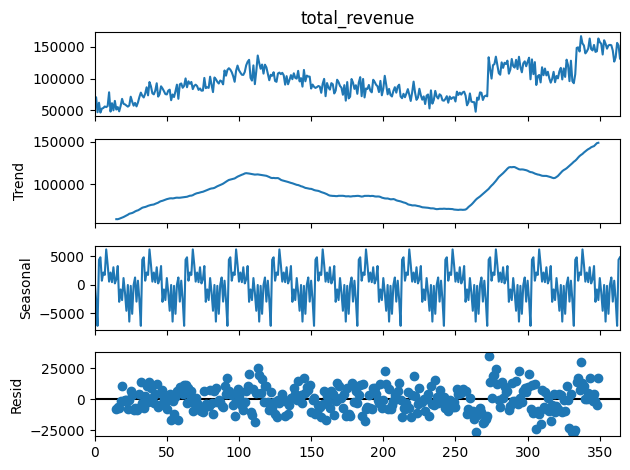

In [50]:
# Visualisiere die Ergebnisse
plt.figure(figsize=(12, 6))
result.plot()
plt.show()

# Fazit

Was konntest du an deinen Analysen ablesen? Was für Werbestrategien würdest du anhand diesen ableiten?

Zu Ostern, in der Weihnachtszeit und zum Monatsende wird mehr verkauft, weshalb mehr Geld für Werbung ausgegeben werden sollte.“

---

## **Optional: Erstellung eines Abschlussberichts**
- Formuliere deine Analyseergebnisse als zusammenhängenden Bericht.
- Struktur des Berichts:
  1. **Einleitung** – Ziele der Analyse
  2. **Datenbeschreibung** – Überblick über die Daten
  3. **Methodik** – Wie wurden die Daten bereinigt und analysiert?
  4. **Ergebnisse** – Wichtige Erkenntnisse mit Diagrammen und Kennzahlen
  5. **Fazit & Handlungsempfehlungen** – Interpretation der Ergebnisse und mögliche Maßnahmen zur Optimierung des Verkaufs.

---

